In [200]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [201]:
#Create a dataframe
df = pd.read_csv("wdbc.data",header=None)

In [202]:
df.shape

(569, 32)

In [203]:
#Check the structure
df.head()

,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [204]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       569 non-null    int64  
 1   1       569 non-null    object 
 2   2       569 non-null    float64
 3   3       569 non-null    float64
 4   4       569 non-null    float64
 5   5       569 non-null    float64
 6   6       569 non-null    float64
 7   7       569 non-null    float64
 8   8       569 non-null    float64
 9   9       569 non-null    float64
 10  10      569 non-null    float64
 11  11      569 non-null    float64
 12  12      569 non-null    float64
 13  13      569 non-null    float64
 14  14      569 non-null    float64
 15  15      569 non-null    float64
 16  16      569 non-null    float64
 17  17      569 non-null    float64
 18  18      569 non-null    float64
 19  19      569 non-null    float64
 20  20      569 non-null    float64
 21  21      569 non-null    float64
 22  22

In [205]:
#Add column names to the DataFrame
df.columns=["ID","Diagnosis","radius1","texture1","perimeter1","area1","smoothness1","compactness1","concavity1","concave_points1","symmetry1","fractal_dimension1","radius2","texture2","perimeter2","area2","smoothness2","compactness2","concavity2","concave_points2","symmetry2","fractal_dimension2","radius3","texture3","perimeter3","area3","smoothness3","compactness3","concavity3","concave_points3","symmetry3","fractal_dimension3"]

In [206]:
#Check dataframe after adding columns
df.head()

,ID,Diagnosis,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [208]:
#Check the DataFrame information after adding column names
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  569 non-null    int64  
 1   Diagnosis           569 non-null    object 
 2   radius1             569 non-null    float64
 3   texture1            569 non-null    float64
 4   perimeter1          569 non-null    float64
 5   area1               569 non-null    float64
 6   smoothness1         569 non-null    float64
 7   compactness1        569 non-null    float64
 8   concavity1          569 non-null    float64
 9   concave_points1     569 non-null    float64
 10  symmetry1           569 non-null    float64
 11  fractal_dimension1  569 non-null    float64
 12  radius2             569 non-null    float64
 13  texture2            569 non-null    float64
 14  perimeter2          569 non-null    float64
 15  area2               569 non-null    float64
 16  smoothne

In [209]:
df.shape

(569, 32)

In [210]:
#Drop the ID column because it is not needed.
#Drop the Diagnosis column because it is the target variable.
#The remaining columns are our features.
X = df.drop(columns=["ID","Diagnosis"])

In [211]:
#Add Diagnosis as our target variable y
y = df["Diagnosis"].map({"M":1,"B":0})

In [212]:
X

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [213]:
y

0      1
1      1
2      1
3      1
4      1
      ..
564    1
565    1
566    1
567    1
568    0
Name: Diagnosis, Length: 569, dtype: int64

In [214]:
#Compute the sigmoid function to convert linear outputs into probabilities
def f_wb(X,w,b):
    z = np.dot(X,w)+b
    return (1/(1+np.exp(-z)))
    

In [215]:
#Compute the cost of logistic regression
def cost(X,y,w,b):
    m = X.shape[0]
    predictions = f_wb(X,w,b)
    cost = np.dot(y,np.log(predictions))+np.dot(1-y,np.log(1-predictions))
    cost *= -(1/m)
    return cost
    

In [218]:
#Compute the gradients
def compute_gradient(X,y,w,b):
    predictions = f_wb(X,w,b)
    m = X.shape[0]
    
    dj_dw = np.dot(X.T,(predictions-y))
    dj_dw *= (1/m)
    
    dj_db = np.sum(predictions-y)
    dj_db *= (1/m)
    
    return dj_dw,dj_db

In [219]:
#Perform gradient descent
def gradient_descent(X,y,w,b,alpha,iterations=1000):
    cost_list = []
    
    for i in range(iterations):
        cost_i = cost(X,y,w,b)
        cost_list.append(cost_i)
        dj_dw,dj_db = compute_gradient(X,y,w,b)
        
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
        
        if (i+1) % 100 == 0:
            print(f"{i+1}th iteration cost is:",cost_i)
            
    return w,b,cost_list
    

In [221]:
#Initial values for W and b
w = np.zeros(X.shape[1])
b = 0

In [222]:
#Split the dataset into training and testing sets
X_train,X_test,y_train,y_test = train_test_split(X,y,train_size=0.8,random_state=11)

In [223]:
print("X_train shape is:",X_train.shape)
print("X_test shape is:",X_test.shape)
print("y_train shape is:",y_train.shape)
print("y_test shape is:",y_test.shape)

X_train shape is: (455, 30)
X_test shape is: (114, 30)
y_train shape is: (455,)
y_test shape is: (114,)


In [224]:
#Standardize the training dataset using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

In [225]:
#Obtain the optimized values of w and b that minimize the cost
best_w,best_b,cost_list=gradient_descent(X_train_scaled,y_train,w,b,alpha=0.01,iterations=1000)

100th iteration cost is: 0.2536342685974594
200th iteration cost is: 0.19131569591284128
300th iteration cost is: 0.16306976356120687
400th iteration cost is: 0.1463049344264882
500th iteration cost is: 0.13497656076351228
600th iteration cost is: 0.126696031263847
700th iteration cost is: 0.12031548901256087
800th iteration cost is: 0.11520997500763684
900th iteration cost is: 0.11100770169892665
1000th iteration cost is: 0.10747230214332723


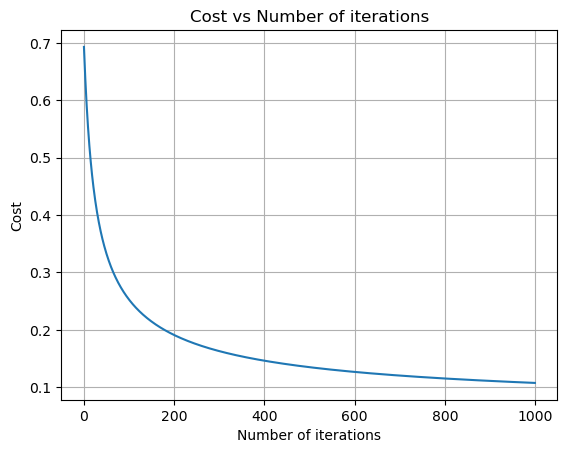

In [226]:
#Plot the cost against the number of iteration
plt.title("Cost vs Number of iterations")
plt.plot(cost_list)
plt.xlabel("Number of iterations")
plt.ylabel("Cost")
plt.grid(True)
plt.show()


In [227]:
#Prediction function for a single patient
def predict_one(X_new,best_w,best_b):
    scaled_sample = scaler.transform(X_new.reshape(1,-1))
    z = np.dot(scaled_sample,best_w)+ best_b
    prediction = (1/(1+np.exp(-z)))

    if prediction >= 0.5:
        return 1
    else:
        return 0

In [228]:
#Prediction function for multiple patients
def predict(X_new,best_w,best_b):
    scaled_X = scaler.transform(X_new)
    z = np.dot(scaled_X,best_w)+ best_b
    prediction = (1/(1+np.exp(-z)))

    results = np.where(prediction >= 0.5,1,0)
    
    return results
    

In [229]:
#Function for checking the accuracy of the trained model
def accuracy(X,y,w,b):
    predictions = predict(X,w,b)
    count = np.sum(predictions == y)
    acc = count/len(y)*100
    return acc

In [230]:
sample = X_test.iloc[0].values
result = predict_one(sample,best_w,best_b)
actual_value = y_test.iloc[0]
print("Predicted value:",result)
print("Actual value:",actual_value)

Predicted value: 1
Actual value: 1


C:\ProgramData\Anaconda3\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [231]:
sample = X_test.iloc[:10].values
results = predict(sample,best_w,best_b)
actual_values = y_test.iloc[:10].values
print("Predicted values:",results)
print("Actual values:",actual_values)

Predicted values: [1 1 1 1 1 0 1 0 0 0]
Actual values: [1 1 1 1 1 0 1 0 0 0]


C:\ProgramData\Anaconda3\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [232]:
print(f"Accuracy on the test set is:{accuracy(X_test,y_test,best_w,best_b):.2f}%")

Accuracy on the test set is:97.37%
